<a href="https://colab.research.google.com/github/MaryamAliAljallaf/AIS-data-test-1/blob/main/OpenOceanNetwork_AIS_Test.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

reference for the columns

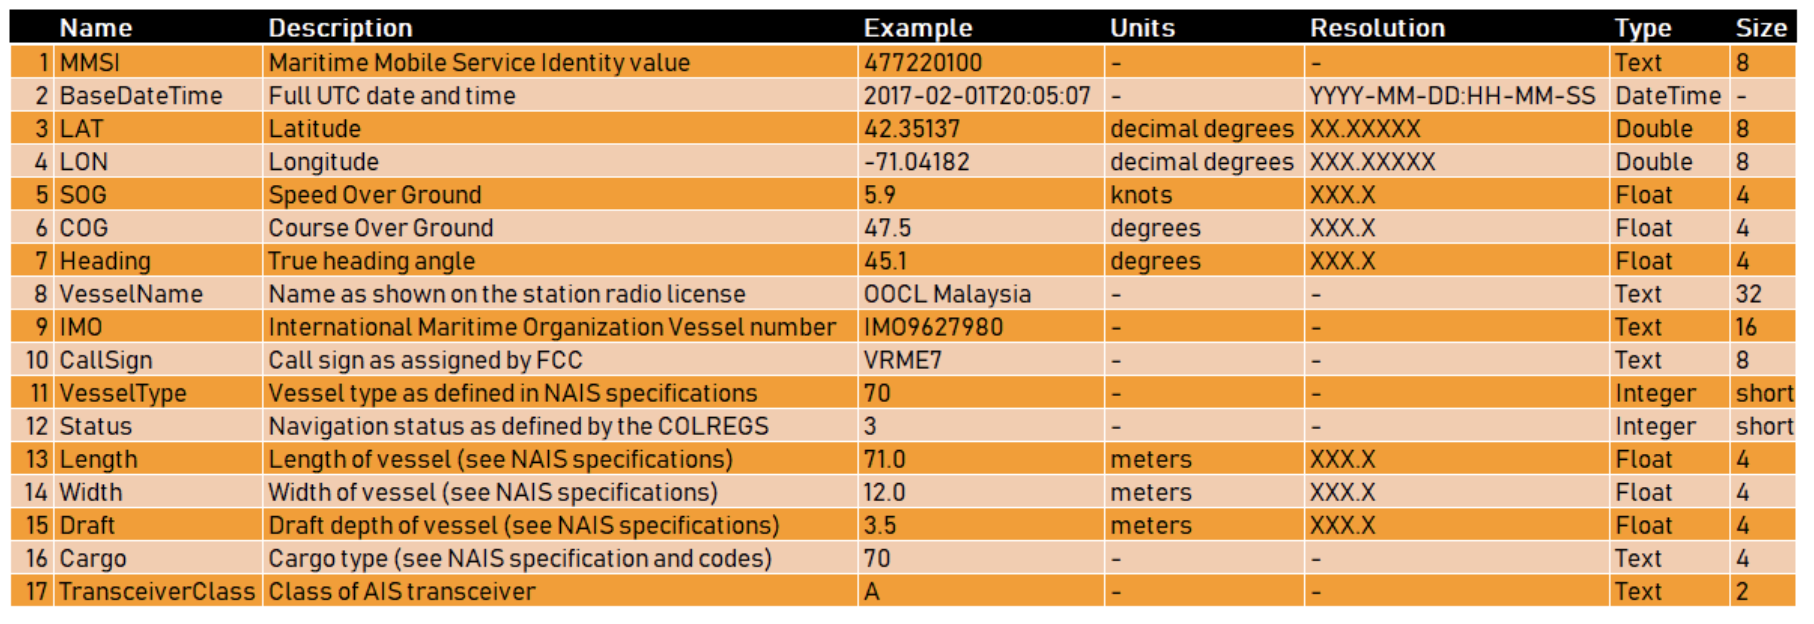

In [2]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
import os

folder = "/content/drive/MyDrive"

files = [
    "2023_NOAA_AIS_logs_01.parquet",
    "2023_NOAA_AIS_logs_02.parquet",
    "2023_NOAA_AIS_ships_01.parquet",
    "2023_NOAA_AIS_ships_02.parquet"
]

for filename in files:
    path = os.path.join(folder, filename)

    if os.path.exists(path):
        size = os.path.getsize(path) / 1e9
        print(f"FOUND: {filename} ({size:.2f} GB)")
    else:
        print(f"NOT FOUND: {filename}")

FOUND: 2023_NOAA_AIS_logs_01.parquet (3.39 GB)
FOUND: 2023_NOAA_AIS_logs_02.parquet (2.90 GB)
FOUND: 2023_NOAA_AIS_ships_01.parquet (0.00 GB)
FOUND: 2023_NOAA_AIS_ships_02.parquet (0.00 GB)


**Step 1 — Validate the datasets**

Check AIS movements and ship characteristics.

In [4]:
import pyarrow.parquet as pq

for filename in files:
    path = os.path.join(folder, filename)

    print("\n" + "=" * 60)
    print("FILE:", filename)

    if not os.path.exists(path):
        print("FILE NOT FOUND")
        continue

    pf = pq.ParquetFile(path)

    print("Total rows:", f"{pf.metadata.num_rows:,}")
    print("Columns:", pf.schema.names)
    print("\nFirst 5 records:")

    if pf.metadata.num_rows > 0:
        batch = next(pf.iter_batches(batch_size=5))
        display(batch.to_pandas())


FILE: 2023_NOAA_AIS_logs_01.parquet
Total rows: 242,779,878
Columns: ['MMSI', 'BaseDateTime', 'LAT', 'LON', 'SOG', 'COG', 'Heading']

First 5 records:


,MMSI,BaseDateTime,LAT,LON,SOG,COG,Heading
0,129129903,2023-01-01,18.81136,-66.46386,6.5,338.8,338.0
1,209920000,2023-01-01,28.86785,-89.39993,6.2,48.3,50.0
2,212259000,2023-01-01,48.42268,-123.37375,0.0,335.9,321.0
3,215567000,2023-01-01,26.25989,-79.05443,14.3,273.9,275.0
4,241454000,2023-01-01,29.10736,-94.41600,7.9,3.6,6.0



FILE: 2023_NOAA_AIS_logs_02.parquet
Total rows: 207,511,685
Columns: ['MMSI', 'BaseDateTime', 'LAT', 'LON', 'SOG', 'COG', 'Heading']

First 5 records:


,MMSI,BaseDateTime,LAT,LON,SOG,COG,Heading
0,209575000,2023-02-01,31.82485,-80.51479,8.8,132.9,129.0
1,241764000,2023-02-01,16.92629,-65.56351,2.5,275.4,303.0
2,247310400,2023-02-01,37.82931,-76.16935,14.8,358.0,0.0
3,247320400,2023-02-01,26.64666,-79.85152,25.6,9.8,10.0
4,257091890,2023-02-01,26.81927,-83.36906,13.2,201.5,202.0



FILE: 2023_NOAA_AIS_ships_01.parquet
Total rows: 33,716
Columns: ['MMSI', 'VesselName', 'IMO', 'CallSign', 'VesselType', 'Status', 'Length', 'Width', 'Draft', 'Cargo', 'TransceiverClass', 'BaseDateTime']

First 5 records:


,MMSI,VesselName,IMO,CallSign,VesselType,Status,Length,Width,Draft,Cargo,TransceiverClass,BaseDateTime
0,0,<Unknown>,<Unknown>,<Unknown>,0.0,NaN,14.0,4.0,0.0,0.0,B,2023-01-03 19:47:28
1,1,A,IMO0999999,A,60.0,5.0,88.0,18.0,4.0,60.0,A,2023-01-01 00:01:36
2,11,CONSTITUTION,IMO0000007,GC 680,90.0,5.0,53.0,38.0,0.0,90.0,A,2023-01-01 00:08:03
3,111,BOOMVANG,IMO0000001,EB643,90.0,5.0,47.0,35.0,0.0,90.0,A,2023-01-01 00:01:19
4,368926,US GOVT VESSEL,IMO0004371,<Unknown>,35.0,3.0,128.0,32.0,0.0,35.0,A,2023-01-18 16:52:56



FILE: 2023_NOAA_AIS_ships_02.parquet
Total rows: 32,435
Columns: ['MMSI', 'VesselName', 'IMO', 'CallSign', 'VesselType', 'Status', 'Length', 'Width', 'Draft', 'Cargo', 'TransceiverClass', 'BaseDateTime']

First 5 records:


,MMSI,VesselName,IMO,CallSign,VesselType,Status,Length,Width,Draft,Cargo,TransceiverClass,BaseDateTime
0,0,<Unknown>,<Unknown>,<Unknown>,0.0,NaN,14.0,4.0,0.0,0.0,B,2023-02-01 14:20:36
1,1,A,IMO0999999,A,60.0,5.0,88.0,18.0,4.0,60.0,A,2023-02-01 00:08:26
2,11,CONSTITUTION,IMO0000007,GC 680,90.0,5.0,53.0,38.0,0.0,90.0,A,2023-02-07 15:41:53
3,111,BOOMVANG,IMO0000001,EB643,90.0,5.0,47.0,35.0,0.0,90.0,A,2023-02-07 17:03:38
4,607,34PB607,<Unknown>,<Unknown>,0.0,15.0,0.0,0.0,0.0,0.0,A,2023-02-23 18:28:38


In [5]:
import pandas as pd

ship_files = [
    "2023_NOAA_AIS_ships_01.parquet",
    "2023_NOAA_AIS_ships_02.parquet"
]

for filename in ship_files:
    path = os.path.join(folder, filename)
    df = pd.read_parquet(path)

    print("\nFILE:", filename)
    print("Total rows:", len(df))
    print("Unique MMSI:", df["MMSI"].nunique())
    print("Duplicate MMSI:", df["MMSI"].duplicated().sum())

    print("\nMissing values (%):")
    print(
        (df.isna().mean() * 100)
        .round(2)
        .sort_values(ascending=False)
    )

    print("\nTop vessel types:")
    print(df["VesselType"].value_counts().head(15))


FILE: 2023_NOAA_AIS_ships_01.parquet
Total rows: 33716
Unique MMSI: 33716
Duplicate MMSI: 0

Missing values (%):
Draft               72.10
Cargo               56.22
Status              53.30
Width               21.14
Length              11.01
VesselType           4.09
VesselName           0.00
MMSI                 0.00
CallSign             0.00
IMO                  0.00
TransceiverClass     0.00
BaseDateTime         0.00
dtype: float64

Top vessel types:
VesselType
37.0    11948
31.0     3970
36.0     3557
70.0     2927
30.0     2152
90.0     1770
60.0     1614
80.0     1386
52.0      529
51.0      299
0.0       291
57.0      248
71.0      197
33.0      147
99.0      146
Name: count, dtype: int64

FILE: 2023_NOAA_AIS_ships_02.parquet
Total rows: 32435
Unique MMSI: 32435
Duplicate MMSI: 0

Missing values (%):
Draft               72.72
Cargo               57.24
Status              54.34
Width               20.79
Length              10.87
VesselType           3.94
VesselName           0.

In [6]:
jan = pd.read_parquet(
    f"{folder}/2023_NOAA_AIS_ships_01.parquet"
)

feb = pd.read_parquet(
    f"{folder}/2023_NOAA_AIS_ships_02.parquet"
)

# Combine the two months
ships = pd.concat([jan, feb], ignore_index=True)

print("Before cleaning:", len(ships))

# Keep valid nine-digit MMSI identifiers
ships["MMSI"] = pd.to_numeric(
    ships["MMSI"], errors="coerce"
)

ships = ships[
    ships["MMSI"].between(100000000, 999999999)
].copy()

# Keep the most recent ship record for each MMSI
ships["BaseDateTime"] = pd.to_datetime(
    ships["BaseDateTime"], errors="coerce"
)

ships = (
    ships.sort_values("BaseDateTime")
    .drop_duplicates(subset="MMSI", keep="last")
)

print("After cleaning:", len(ships))
print("Unique vessels:", ships["MMSI"].nunique())

display(ships.head())

# Save the combined ship information
ships.to_parquet(
    f"{folder}/ships_combined_2023.parquet",
    index=False
)

print("Saved: ships_combined_2023.parquet")

Before cleaning: 66151
After cleaning: 40843
Unique vessels: 40843


,MMSI,VesselName,IMO,CallSign,VesselType,Status,Length,Width,Draft,Cargo,TransceiverClass,BaseDateTime
29369,369309000,MAERSK SELETAR,IMO9315197,WTAA,70.0,2.0,318.0,40.0,14.0,70.0,A,2023-01-01
32825,636018070,ARISTOMENIS,IMO9408841,D5OA5,70.0,0.0,349.0,45.0,15.0,71.0,A,2023-01-01
2494,316004053,W J IVAN PURVIS,IMO5217218,VCBM,31.0,7.0,29.0,7.0,2.7,90.0,A,2023-01-01
29021,368293000,ALASKA OCEAN,IMO8030477,KRCT,30.0,0.0,114.0,18.0,3.6,30.0,A,2023-01-01
32731,636016742,TREASURE,IMO9184859,D5HO2,70.0,0.0,199.0,32.0,10.0,70.0,A,2023-01-01


Saved: ships_combined_2023.parquet


In [7]:
#perserving the the full original data

jan = pd.read_parquet(
    f"{folder}/2023_NOAA_AIS_ships_01.parquet"
)

feb = pd.read_parquet(
    f"{folder}/2023_NOAA_AIS_ships_02.parquet"
)

# Combine without removing repeated MMSIs
ships_history = pd.concat(
    [jan, feb],
    ignore_index=True
)

# Preserve all original ship-information records
ships_history.to_parquet(
    f"{folder}/ships_history_2023.parquet",
    index=False
)

print("Total ship-information records:", len(ships_history))
print("Unique MMSIs:", ships_history["MMSI"].nunique())
print(
    "Repeated MMSI records:",
    ships_history["MMSI"].duplicated().sum()
)

Total ship-information records: 66151
Unique MMSIs: 40960
Repeated MMSI records: 25191


Check the quality of AIS movement data.

In [8]:

path = "/content/drive/MyDrive/2023_NOAA_AIS_logs_01.parquet"

pf = pq.ParquetFile(path)

# Read only 100,000 rows for an initial quality check
df = next(pf.iter_batches(batch_size=100_000)).to_pandas()

print("Sample rows:", len(df))

print("\nMissing values (%):")
print((df.isna().mean() * 100).round(2))

print("\nInvalid coordinates:")
print("Invalid latitude:", (~df["LAT"].between(-90, 90)).sum())
print("Invalid longitude:", (~df["LON"].between(-180, 180)).sum())

print("\nDuplicate observations:")
print(df.duplicated(
    subset=["MMSI", "BaseDateTime", "LAT", "LON"]
).sum())

print("\nUnique vessels:", df["MMSI"].nunique())

Sample rows: 100000

Missing values (%):
MMSI            0.0
BaseDateTime    0.0
LAT             0.0
LON             0.0
SOG             0.0
COG             0.0
Heading         0.0
dtype: float64

Invalid coordinates:
Invalid latitude: 0
Invalid longitude: 0

Duplicate observations:
0

Unique vessels: 12396


In [9]:
#Check AIS speed, course and heading
print("Speed (SOG):")
print("Minimum:", df["SOG"].min())
print("Maximum:", df["SOG"].max())
print("SOG >= 102.3:", (df["SOG"] >= 102.3).sum())

print("\nCourse (COG):")
print("Minimum:", df["COG"].min())
print("Maximum:", df["COG"].max())
print("COG >= 360:", (df["COG"] >= 360).sum())

print("\nHeading:")
print("Minimum:", df["Heading"].min())
print("Maximum:", df["Heading"].max())
print("Heading == 511:", (df["Heading"] == 511).sum())

print("\nMost common SOG values:")
print(df["SOG"].value_counts().head(10))

Speed (SOG):
Minimum: 0.0
Maximum: 102.3
SOG >= 102.3: 249

Course (COG):
Minimum: 0.0
Maximum: 360.0
COG >= 360: 14607

Heading:
Minimum: 0.0
Maximum: 511.0
Heading == 511: 50105

Most common SOG values:
SOG
0.0    62283
0.1     6817
0.2     1631
0.3      868
0.4      644
0.5      502
0.6      437
0.7      410
0.8      337
4.7      313
Name: count, dtype: int64


In [10]:
import numpy as np

# Create a copy so the original sample remains unchanged
df_clean = df.copy()

# Replace unavailable AIS measurements with NaN
df_clean.loc[df_clean["SOG"] >= 102.3, "SOG"] = np.nan
df_clean.loc[df_clean["COG"] >= 360, "COG"] = np.nan
df_clean.loc[df_clean["Heading"] == 511, "Heading"] = np.nan

print("Missing values after cleaning (%):")
print((df_clean.isna().mean() * 100).round(2))

print("\nFirst 5 cleaned records:")
display(df_clean.head())

Missing values after cleaning (%):
MMSI             0.00
BaseDateTime     0.00
LAT              0.00
LON              0.00
SOG              0.25
COG             14.61
Heading         50.10
dtype: float64

First 5 cleaned records:


,MMSI,BaseDateTime,LAT,LON,SOG,COG,Heading
0,129129903,2023-01-01,18.81136,-66.46386,6.5,338.8,338.0
1,209920000,2023-01-01,28.86785,-89.39993,6.2,48.3,50.0
2,212259000,2023-01-01,48.42268,-123.37375,0.0,335.9,321.0
3,215567000,2023-01-01,26.25989,-79.05443,14.3,273.9,275.0
4,241454000,2023-01-01,29.10736,-94.41600,7.9,3.6,6.0


In [11]:
#Check vessel observations over time
# Convert timestamps to datetime
df_clean["BaseDateTime"] = pd.to_datetime(
    df_clean["BaseDateTime"],
    utc=True,
    errors="coerce"
)

# Count observations for each vessel
vessel_counts = df_clean["MMSI"].value_counts()

print("Unique vessels:", len(vessel_counts))
print("Vessels with more than one observation:",
      (vessel_counts > 1).sum())

print("\nObservations per vessel:")
print(vessel_counts.describe())

# Show the observations of one frequently recorded vessel
example_mmsi = vessel_counts.index[0]

print("\nExample vessel MMSI:", example_mmsi)

display(
    df_clean[df_clean["MMSI"] == example_mmsi]
    .sort_values("BaseDateTime")
    .head(10)
)

Unique vessels: 12396
Vessels with more than one observation: 11888

Observations per vessel:
count    12396.000000
mean         8.067118
std          5.053407
min          1.000000
25%          4.000000
50%          6.000000
75%         14.000000
max         17.000000
Name: count, dtype: float64

Example vessel MMSI: 366902000


,MMSI,BaseDateTime,LAT,LON,SOG,COG,Heading
434,366902000,2023-01-01 00:00:01+00:00,28.93032,-90.48201,8.8,234.4,144.0
6733,366902000,2023-01-01 00:01:04+00:00,28.92897,-90.48453,8.9,238.5,143.0
12775,366902000,2023-01-01 00:02:05+00:00,28.92769,-90.48698,8.8,242.2,146.0
19307,366902000,2023-01-01 00:03:07+00:00,28.92646,-90.48954,8.9,243.3,151.0
25720,366902000,2023-01-01 00:04:09+00:00,28.92515,-90.49188,8.7,237.2,144.0
31994,366902000,2023-01-01 00:05:10+00:00,28.92388,-90.49435,8.7,243.5,154.0
38307,366902000,2023-01-01 00:06:11+00:00,28.92263,-90.49665,8.6,237.6,148.0
44574,366902000,2023-01-01 00:07:14+00:00,28.92127,-90.49916,8.7,240.5,157.0
50330,366902000,2023-01-01 00:08:15+00:00,28.91997,-90.50153,8.9,236.2,151.0
56257,366902000,2023-01-01 00:09:18+00:00,28.91853,-90.50399,8.8,232.1,147.0


In [12]:
#Check whether vessel information can be connected to AIS movements

# Load the ship-information history
ships_history = pd.read_parquet(
    f"{folder}/ships_history_2023.parquet"
)

# Identify MMSIs present in both datasets
ais_mmsi = set(df_clean["MMSI"].dropna())
ship_mmsi = set(ships_history["MMSI"].dropna())

matched = ais_mmsi.intersection(ship_mmsi)

print("Unique AIS vessels in sample:", len(ais_mmsi))
print("Unique vessels in ship information:", len(ship_mmsi))
print("Matching vessels:", len(matched))

print(
    "Matching percentage:",
    round(len(matched) / len(ais_mmsi) * 100, 2),
    "%"
)

# Preview ship information for matching vessels
matching_ships = ships_history[
    ships_history["MMSI"].isin(matched)
]

display(
    matching_ships[
        ["MMSI", "VesselName", "VesselType", "Length", "Width"]
    ].head(10)
)

Unique AIS vessels in sample: 12396
Unique vessels in ship information: 40960
Matching vessels: 12396
Matching percentage: 100.0 %


,MMSI,VesselName,VesselType,Length,Width
1,1,A,60.0,88.0,18.0
2,11,CONSTITUTION,90.0,53.0,38.0
3,111,BOOMVANG,90.0,47.0,35.0
5,1056261,CHAMPAGNE CHER,10.0,35.0,8.0
13,3660489,NEPTUNE TLP,90.0,NaN,NaN
14,3660512,PERDIDO,90.0,169.0,0.0
15,3669881,<Unknown>,0.0,0.0,0.0
16,3669882,<Unknown>,0.0,0.0,0.0
20,3791472,LUCIUS SPAR,80.0,0.0,0.0
36,9110192,<Unknown>,NaN,NaN,NaN


In [13]:
#Test the merge safely
# Load the simplified ship lookup
ships_lookup = pd.read_parquet(
    f"{folder}/ships_combined_2023.parquet"
)

# Select only useful ship characteristics
ships_lookup = ships_lookup[
    ["MMSI", "VesselName", "VesselType", "Length", "Width"]
]

# Merge with our cleaned AIS sample
ais_merged = df_clean.merge(
    ships_lookup,
    on="MMSI",
    how="left",
    validate="many_to_one"
)

print("AIS rows before merge:", len(df_clean))
print("AIS rows after merge:", len(ais_merged))

print(
    "Rows with matched vessel type:",
    ais_merged["VesselType"].notna().sum()
)

print(
    "Rows with missing vessel type:",
    ais_merged["VesselType"].isna().sum()
)

display(ais_merged.head(10))

AIS rows before merge: 100000
AIS rows after merge: 100000
Rows with matched vessel type: 99886
Rows with missing vessel type: 114


,MMSI,BaseDateTime,LAT,LON,SOG,COG,Heading,VesselName,VesselType,Length,Width
0,129129903,2023-01-01 00:00:00+00:00,18.81136,-66.46386,6.5,338.8,338.0,DRAGON FIRE,36.0,16.0,5.0
1,209920000,2023-01-01 00:00:00+00:00,28.86785,-89.39993,6.2,48.3,50.0,CMA CGM NABUCCO,73.0,334.0,42.0
2,212259000,2023-01-01 00:00:00+00:00,48.42268,-123.37375,0.0,335.9,321.0,HALUNDER JET,60.0,51.0,12.0
3,215567000,2023-01-01 00:00:00+00:00,26.25989,-79.05443,14.3,273.9,275.0,COOL DISCOVERER,89.0,299.0,46.0
4,241454000,2023-01-01 00:00:00+00:00,29.10736,-94.41600,7.9,3.6,6.0,LEONTIOS H,80.0,249.0,NaN
5,244848000,2023-01-01 00:00:00+00:00,29.74529,-95.10258,6.9,45.2,44.0,DONAUGRACHT,70.0,156.0,22.0
6,245639000,2023-01-01 00:00:00+00:00,37.78865,-76.17859,12.0,14.0,15.0,FRASERBORG,70.0,154.0,17.0
7,248546000,2023-01-01 00:00:00+00:00,30.05423,-90.49384,0.0,255.0,270.0,ANATOLI,70.0,199.0,32.0
8,255806038,2023-01-01 00:00:00+00:00,34.89502,-75.31610,23.7,44.9,44.0,NORTHERN JUBILEE,70.0,333.0,43.0
9,256074000,2023-01-01 00:00:00+00:00,28.55186,-93.41575,13.5,305.2,307.0,PS HAMBURG,80.0,183.0,32.0


In [14]:
#Examine the types of vessels in our dataset
# Categorize vessels by AIS type codes

def classify_vessel(code):
    if pd.isna(code):
        return "Unknown"

    code = int(code)

    if 70 <= code <= 79:
        return "Cargo"
    elif 80 <= code <= 89:
        return "Tanker"
    elif 60 <= code <= 69:
        return "Passenger"
    elif 30 <= code <= 39:
        return "Special-purpose"
    else:
        return "Other / Unknown"

ais_merged["VesselCategory"] = (
    ais_merged["VesselType"].apply(classify_vessel)
)

print("AIS observations by vessel category:")
print(ais_merged["VesselCategory"].value_counts())

print("\nUnique MMSIs by vessel category:")
print(
    ais_merged.groupby("VesselCategory")["MMSI"]
    .nunique()
    .sort_values(ascending=False)
)

AIS observations by vessel category:
VesselCategory
Special-purpose    62719
Other / Unknown    16605
Passenger           8210
Cargo               8019
Tanker              4333
Unknown              114
Name: count, dtype: int64

Unique MMSIs by vessel category:
VesselCategory
Special-purpose    8443
Other / Unknown    1646
Cargo               986
Passenger           783
Tanker              522
Unknown              16
Name: MMSI, dtype: int64


**Why this matters**
A fishing boat moving slowly near a port is not necessarily evidence of commercial port congestion.
By identifying vessel categories, we can later decide which vessels to include when calculating congestion indicators.

In [15]:
#Check commercial vessel movements
# Select cargo and tanker observations
commercial_sample = ais_merged[
    ais_merged["VesselCategory"].isin(["Cargo", "Tanker"])
].copy()

print("Commercial AIS observations:", len(commercial_sample))

print(
    "Unique commercial vessels:",
    commercial_sample["MMSI"].nunique()
)

print("\nSpeed statistics:")
print(commercial_sample["SOG"].describe())

print("\nCommercial observations with SOG <= 0.5 knots:")
print((commercial_sample["SOG"] <= 0.5).sum())

print("\nFirst 10 commercial vessel observations:")
display(
    commercial_sample[
        ["MMSI", "BaseDateTime", "LAT", "LON",
         "SOG", "VesselCategory", "Length"]
    ].head(10)
)

Commercial AIS observations: 12352
Unique commercial vessels: 1508

Speed statistics:
count    12352.000000
mean         5.905538
std          6.419062
min          0.000000
25%          0.000000
50%          1.500000
75%         12.100000
max         24.000000
Name: SOG, dtype: float64

Commercial observations with SOG <= 0.5 knots:
5650

First 10 commercial vessel observations:


,MMSI,BaseDateTime,LAT,LON,SOG,VesselCategory,Length
1,209920000,2023-01-01 00:00:00+00:00,28.86785,-89.39993,6.2,Cargo,334.0
3,215567000,2023-01-01 00:00:00+00:00,26.25989,-79.05443,14.3,Tanker,299.0
4,241454000,2023-01-01 00:00:00+00:00,29.10736,-94.41600,7.9,Tanker,249.0
5,244848000,2023-01-01 00:00:00+00:00,29.74529,-95.10258,6.9,Cargo,156.0
6,245639000,2023-01-01 00:00:00+00:00,37.78865,-76.17859,12.0,Cargo,154.0
7,248546000,2023-01-01 00:00:00+00:00,30.05423,-90.49384,0.0,Cargo,199.0
8,255806038,2023-01-01 00:00:00+00:00,34.89502,-75.31610,23.7,Cargo,333.0
9,256074000,2023-01-01 00:00:00+00:00,28.55186,-93.41575,13.5,Tanker,183.0
10,257990000,2023-01-01 00:00:00+00:00,16.83008,-65.39873,14.8,Tanker,277.0
11,271043028,2023-01-01 00:00:00+00:00,31.98554,-79.37248,15.8,Cargo,182.0


In [16]:
#Check the time coverage of the sample
print("Earliest observation:",
      commercial_sample["BaseDateTime"].min())

print("Latest observation:",
      commercial_sample["BaseDateTime"].max())

duration = (
    commercial_sample["BaseDateTime"].max()
    - commercial_sample["BaseDateTime"].min()
)

print("Sample duration:", duration)

print("\nObservations by hour:")
print(
    commercial_sample
    .groupby(
        commercial_sample["BaseDateTime"].dt.floor("h")
    )
    .size()
)

Earliest observation: 2023-01-01 00:00:00+00:00
Latest observation: 2023-01-01 00:16:40+00:00
Sample duration: 0 days 00:16:40

Observations by hour:
BaseDateTime
2023-01-01 00:00:00+00:00    12352
dtype: int64


This confirms that our sample was useful for testing cleaning and merging, but it is too short for multi-horizon congestion prediction.

In [17]:
#Test full-file processing without loading everything into memory
for filename in files:
    path = os.path.join(folder, filename)
    pf = pq.ParquetFile(path)

    print("\nFILE:", filename)
    print("Total rows:", f"{pf.metadata.num_rows:,}")

    # Read only the first 3 batches to test processing
    for i, batch in enumerate(
        pf.iter_batches(batch_size=100_000)
    ):
        print(
            f"Batch {i+1}:",
            f"{batch.num_rows:,} records"
        )

        if i == 2:
            break

print("\nBatch processing test completed.")


FILE: 2023_NOAA_AIS_logs_01.parquet
Total rows: 242,779,878
Batch 1: 100,000 records
Batch 2: 100,000 records
Batch 3: 100,000 records

FILE: 2023_NOAA_AIS_logs_02.parquet
Total rows: 207,511,685
Batch 1: 100,000 records
Batch 2: 100,000 records
Batch 3: 100,000 records

FILE: 2023_NOAA_AIS_ships_01.parquet
Total rows: 33,716
Batch 1: 33,716 records

FILE: 2023_NOAA_AIS_ships_02.parquet
Total rows: 32,435
Batch 1: 32,435 records

Batch processing test completed.


In [18]:
#Check commercial vessel coverage across both months

# Select cargo and tanker MMSIs
commercial_mmsi = set(
    ships.loc[
        ships["VesselType"].between(70, 89),
        "MMSI"
    ]
)

print("Commercial MMSIs in ship lookup:", len(commercial_mmsi))

files = [
    "2023_NOAA_AIS_logs_01.parquet",
    "2023_NOAA_AIS_logs_02.parquet"
]

daily_counts = {}

for filename in files:
    print("\nProcessing:", filename)

    pf = pq.ParquetFile(
        os.path.join(folder, filename)
    )

    for batch in pf.iter_batches(
        batch_size=250_000,
        columns=["MMSI", "BaseDateTime"]
    ):
        chunk = batch.to_pandas()

        # Keep commercial vessel observations
        chunk = chunk[
            chunk["MMSI"].isin(commercial_mmsi)
        ]

        if chunk.empty:
            continue

        dates = pd.to_datetime(
            chunk["BaseDateTime"],
            errors="coerce"
        ).dt.date

        for date, count in dates.value_counts().items():
            daily_counts[date] = (
                daily_counts.get(date, 0) + count
            )

    print("Finished:", filename)

# Convert results into a table
daily_df = pd.DataFrame(
    sorted(daily_counts.items()),
    columns=["Date", "AIS_Observations"]
)

print("\nDays with commercial observations:", len(daily_df))
print("Total commercial observations:", daily_df["AIS_Observations"].sum())

display(daily_df.head(10))
display(daily_df.tail(10))

Commercial MMSIs in ship lookup: 6465

Processing: 2023_NOAA_AIS_logs_01.parquet
Finished: 2023_NOAA_AIS_logs_01.parquet

Processing: 2023_NOAA_AIS_logs_02.parquet
Finished: 2023_NOAA_AIS_logs_02.parquet

Days with commercial observations: 59
Total commercial observations: 51931458


,Date,AIS_Observations
0,2023-01-01,948178
1,2023-01-02,952069
2,2023-01-03,969932
3,2023-01-04,918322
4,2023-01-05,834782
5,2023-01-06,978124
6,2023-01-07,1004143
7,2023-01-08,961241
8,2023-01-09,972714
9,2023-01-10,947997


,Date,AIS_Observations
49,2023-02-19,847000
50,2023-02-20,908124
51,2023-02-21,907671
52,2023-02-22,888629
53,2023-02-23,927268
54,2023-02-24,948123
55,2023-02-25,851246
56,2023-02-26,863738
57,2023-02-27,927497
58,2023-02-28,967746


In [19]:
#Save daily coverage results
# Ensure dates are sorted
daily_df = daily_df.sort_values("Date").reset_index(drop=True)

# Save the daily counts
output_path = os.path.join(
    folder,
    "commercial_AIS_daily_coverage_2023.csv"
)

daily_df.to_csv(output_path, index=False)

print("Saved:", output_path)
print("Days:", len(daily_df))
print("Total observations:", daily_df["AIS_Observations"].sum())

# Verify there are no missing calendar dates
expected_dates = pd.date_range(
    "2023-01-01",
    "2023-02-28",
    freq="D"
)

actual_dates = pd.to_datetime(daily_df["Date"])
missing_dates = expected_dates.difference(actual_dates)

print("Missing dates:", len(missing_dates))
print("Missing date list:", missing_dates.tolist())

Saved: /content/drive/MyDrive/commercial_AIS_daily_coverage_2023.csv
Days: 59
Total observations: 51931458
Missing dates: 0
Missing date list: []


In [20]:
# Temporary study-area configuration
# Approximate Houston / Galveston coastal region

port_config = {
    "name": "Houston_Test",
    "min_lat": 28.8,
    "max_lat": 30.1,
    "min_lon": -95.5,
    "max_lon": -94.3
}

print("Study area:", port_config["name"])
print("Latitude range:",
      port_config["min_lat"],
      "to",
      port_config["max_lat"])

print("Longitude range:",
      port_config["min_lon"],
      "to",
      port_config["max_lon"])

Study area: Houston_Test
Latitude range: 28.8 to 30.1
Longitude range: -95.5 to -94.3


This is a broad preliminary bounding box, not a validated port or anchorage boundary. It will include some waters and areas outside the port itself.
Later, we'll distinguish between:
- Port approaches
- Anchorage areas
- Terminal or berth areas
Those distinctions are necessary before we can estimate waiting vessels and congestion.

**Step 2 — Select a port**

Choose one US port and define its geographic area.

In [21]:

log_path = os.path.join(
    folder,
    "2023_NOAA_AIS_logs_01.parquet"
)

# Read one batch only
pf = pq.ParquetFile(log_path)

batch = next(
    pf.iter_batches(
        batch_size=500_000,
        columns=["MMSI", "BaseDateTime", "LAT", "LON", "SOG"]
    )
)

chunk = batch.to_pandas()

# Use our temporary Houston bounding box
houston_sample = chunk[
    chunk["LAT"].between(
        port_config["min_lat"],
        port_config["max_lat"]
    )
    &
    chunk["LON"].between(
        port_config["min_lon"],
        port_config["max_lon"]
    )
].copy()

# Filter to cargo/tanker MMSIs from our existing lookup
ships_lookup = pd.read_parquet(
    os.path.join(folder, "ships_combined_2023.parquet"),
    columns=["MMSI", "VesselType"]
)

commercial_mmsi = set(
    ships_lookup.loc[
        ships_lookup["VesselType"].between(70, 89),
        "MMSI"
    ]
)

houston_commercial_sample = houston_sample[
    houston_sample["MMSI"].isin(commercial_mmsi)
].copy()

print("AIS records examined:", len(chunk))
print("Houston area records:", len(houston_sample))
print("Houston commercial records:", len(houston_commercial_sample))
print(
    "Unique commercial vessels:",
    houston_commercial_sample["MMSI"].nunique()
)

display(houston_commercial_sample.head())

AIS records examined: 500000
Houston area records: 36110
Houston commercial records: 5560
Unique commercial vessels: 171


,MMSI,BaseDateTime,LAT,LON,SOG
4,241454000,2023-01-01 00:00:00,29.10736,-94.41600,7.9
5,244848000,2023-01-01 00:00:00,29.74529,-95.10258,6.9
379,311000225,2023-01-01 00:00:01,28.82879,-94.43478,11.7
782,374113000,2023-01-01 00:00:01,29.72617,-95.26220,4.5
815,255806183,2023-01-01 00:00:02,29.73478,-95.13376,7.5


In [23]:
import pyarrow as pa
log_files = [
    "2023_NOAA_AIS_logs_01.parquet",
    "2023_NOAA_AIS_logs_02.parquet"
]

output_path = os.path.join(
    folder,
    "houston_commercial_AIS_2023.parquet"
)

columns = [
    "MMSI",
    "BaseDateTime",
    "LAT",
    "LON",
    "SOG",
    "COG",
    "Heading"
]

writer = None
total_scanned = 0
total_saved = 0

try:
    for filename in log_files:
        print("\nProcessing:", filename)

        pf = pq.ParquetFile(
            os.path.join(folder, filename)
        )

        file_saved = 0

        for batch in pf.iter_batches(
            batch_size=250_000,
            columns=columns
        ):
            chunk = batch.to_pandas()
            total_scanned += len(chunk)

            # Geographic filter
            mask = (
                chunk["LAT"].between(
                    port_config["min_lat"],
                    port_config["max_lat"]
                )
                &
                chunk["LON"].between(
                    port_config["min_lon"],
                    port_config["max_lon"]
                )
                &
                chunk["MMSI"].isin(commercial_mmsi)
            )

            selected = chunk.loc[mask, columns]

            if selected.empty:
                continue

            table = pa.Table.from_pandas(
                selected,
                preserve_index=False
            )

            if writer is None:
                writer = pq.ParquetWriter(
                    output_path,
                    table.schema,
                    compression="snappy"
                )

            writer.write_table(table)

            file_saved += len(selected)
            total_saved += len(selected)

        print("Commercial Houston records saved:", file_saved)

finally:
    if writer is not None:
        writer.close()

print("\nExtraction completed.")
print("Total AIS records scanned:", total_scanned)
print("Total Houston commercial records:", total_saved)
print("Saved file:", output_path)


Processing: 2023_NOAA_AIS_logs_01.parquet
Commercial Houston records saved: 2513188

Processing: 2023_NOAA_AIS_logs_02.parquet
Commercial Houston records saved: 1992438

Extraction completed.
Total AIS records scanned: 450291563
Total Houston commercial records: 4505626
Saved file: /content/drive/MyDrive/houston_commercial_AIS_2023.parquet


In [24]:
#Clean the extracted AIS data
input_path = os.path.join(
    folder,
    "houston_commercial_AIS_2023.parquet"
)

output_path = os.path.join(
    folder,
    "houston_commercial_AIS_clean_2023.parquet"
)

# Load the extracted Houston dataset
ais = pd.read_parquet(input_path)

print("Original records:", len(ais))

# Convert timestamps
ais["BaseDateTime"] = pd.to_datetime(
    ais["BaseDateTime"],
    utc=True,
    errors="coerce"
)

# Replace invalid AIS placeholder values with NaN
ais.loc[ais["SOG"] >= 102.3, "SOG"] = float("nan")
ais.loc[ais["COG"] >= 360, "COG"] = float("nan")
ais.loc[ais["Heading"] == 511, "Heading"] = float("nan")

# Remove records with missing essential information
ais = ais.dropna(
    subset=["MMSI", "BaseDateTime", "LAT", "LON"]
)

# Remove exact duplicate AIS observations
ais = ais.drop_duplicates(
    subset=[
        "MMSI",
        "BaseDateTime",
        "LAT",
        "LON"
    ]
)

# Sort observations chronologically
ais = ais.sort_values(
    ["BaseDateTime", "MMSI"]
).reset_index(drop=True)

# Save cleaned dataset
ais.to_parquet(
    output_path,
    index=False
)

print("Cleaned records:", len(ais))
print("Unique vessels:", ais["MMSI"].nunique())
print("Start:", ais["BaseDateTime"].min())
print("End:", ais["BaseDateTime"].max())
print("Missing SOG (%):", round(ais["SOG"].isna().mean() * 100, 2))
print("Saved:", output_path)

Original records: 4505626
Cleaned records: 4505626
Unique vessels: 1155
Start: 2023-01-01 00:00:00+00:00
End: 2023-02-28 23:59:59+00:00
Missing SOG (%): 0.0
Saved: /content/drive/MyDrive/houston_commercial_AIS_clean_2023.parquet


Why this matters for the LSTM
- We retain valid vessel movements and zero-speed observations.
- We remove invalid AIS placeholder values.
- We remove duplicate observations, not repeated vessel observations at different times.
- We preserve chronological order for time-series modeling.
One limitation remains: we're using the provisional cargo/tanker vessel lookup and a broad geographic box. That is acceptable for building a prototype LSTM, but not yet for claiming verified port congestion prediction.

In [ ]:
#Create hourly congestion indicators


For LSTM prediction, we need a regular time series: one row per hour, rather than millions of individual AIS messages.
We'll create three features:
- Active vessels: distinct commercial vessels observed during each hour.
- Slow vessels: distinct commercial vessels with at least one valid speed observation of 0.5 knots or less during the hour.
- Mean speed: average valid AIS speed reported during the hour.

In [25]:
# Use the cleaned dataset from Step 20
ais = pd.read_parquet(
    os.path.join(
        folder,
        "houston_commercial_AIS_clean_2023.parquet"
    ),
    columns=["MMSI", "BaseDateTime", "SOG"]
)

# Assign every AIS observation to an hourly interval
ais["Hour"] = ais["BaseDateTime"].dt.floor("h")

# Flag slow-speed observations
ais["IsSlow"] = ais["SOG"].le(0.5)

# One row per vessel per hour
vessel_hour = (
    ais.groupby(["Hour", "MMSI"], as_index=False)
       .agg(
           MeanVesselSpeed=("SOG", "mean"),
           HasSlowObservation=("IsSlow", "max")
       )
)

# Aggregate vessels into hourly features
hourly = (
    vessel_hour.groupby("Hour")
    .agg(
        ActiveVessels=("MMSI", "nunique"),
        SlowVessels=("HasSlowObservation", "sum"),
        MeanSpeed=("MeanVesselSpeed", "mean")
    )
)

# Ensure a continuous hourly timeline
all_hours = pd.date_range(
    start="2023-01-01 00:00:00",
    end="2023-02-28 23:00:00",
    freq="h",
    tz="UTC"
)

hourly = hourly.reindex(all_hours)
hourly.index.name = "Hour"

# Missing observation hours are not assumed to mean zero vessels
missing_hours = hourly["ActiveVessels"].isna().sum()

hourly = hourly.reset_index()

output_path = os.path.join(
    folder,
    "houston_hourly_congestion_2023.csv"
)

hourly.to_csv(output_path, index=False)

print("Total hours:", len(hourly))
print("Hours without AIS observations:", missing_hours)

print("\nFirst 5 hours:")
display(hourly.head())

print("\nFeature summary:")
display(
    hourly[
        ["ActiveVessels", "SlowVessels", "MeanSpeed"]
    ].describe()
)

print("\nSaved:", output_path)

Total hours: 1416
Hours without AIS observations: 16

First 5 hours:


,Hour,ActiveVessels,SlowVessels,MeanSpeed
0,2023-01-01 00:00:00+00:00,170.0,152.0,1.232279
1,2023-01-01 01:00:00+00:00,169.0,153.0,1.226672
2,2023-01-01 02:00:00+00:00,169.0,154.0,1.231900
3,2023-01-01 03:00:00+00:00,166.0,152.0,1.052284
4,2023-01-01 04:00:00+00:00,169.0,154.0,1.024467



Feature summary:


,ActiveVessels,SlowVessels,MeanSpeed
count,1400.000000,1400.000000,1400.000000
mean,143.183571,129.911429,1.131905
std,18.492929,18.242764,0.425700
min,1.000000,1.000000,0.000000
25%,130.000000,117.000000,0.851777
50%,138.000000,126.000000,1.140648
75%,158.000000,144.000000,1.422023
max,183.000000,177.000000,2.463996



Saved: /content/drive/MyDrive/houston_hourly_congestion_2023.csv


In [26]:
#Investigate the 16 missing hours
hourly = pd.read_csv(
    "/content/drive/MyDrive/houston_hourly_congestion_2023.csv",
    parse_dates=["Hour"]
)

# Identify hours without AIS observations
missing = hourly[
    hourly["ActiveVessels"].isna()
].copy()

print("Missing hours:", len(missing))

print("\nMissing timestamps:")
display(missing[["Hour"]])

# Identify consecutive missing-hour groups
if not missing.empty:
    missing["GapGroup"] = (
        missing["Hour"].diff() != pd.Timedelta(hours=1)
    ).cumsum()

    gaps = (
        missing.groupby("GapGroup")
        .agg(
            Start=("Hour", "min"),
            End=("Hour", "max"),
            DurationHours=("Hour", "size")
        )
        .reset_index(drop=True)
    )

    print("\nMissing-hour gaps:")
    display(gaps)

Missing hours: 16

Missing timestamps:


,Hour
660,2023-01-28 12:00:00+00:00
661,2023-01-28 13:00:00+00:00
662,2023-01-28 14:00:00+00:00
663,2023-01-28 15:00:00+00:00
664,2023-01-28 16:00:00+00:00
665,2023-01-28 17:00:00+00:00
666,2023-01-28 18:00:00+00:00
667,2023-01-28 19:00:00+00:00
870,2023-02-06 06:00:00+00:00
1039,2023-02-13 07:00:00+00:00



Missing-hour gaps:


,Start,End,DurationHours
0,2023-01-28 12:00:00+00:00,2023-01-28 19:00:00+00:00,8
1,2023-02-06 06:00:00+00:00,2023-02-06 06:00:00+00:00,1
2,2023-02-13 07:00:00+00:00,2023-02-13 12:00:00+00:00,6
3,2023-02-14 06:00:00+00:00,2023-02-14 06:00:00+00:00,1


In [27]:
#Prepare the hourly dataset for LSTM
path = "/content/drive/MyDrive/houston_hourly_congestion_2023.csv"

hourly = pd.read_csv(path, parse_dates=["Hour"])
hourly = hourly.sort_values("Hour").reset_index(drop=True)

features = ["ActiveVessels", "SlowVessels", "MeanSpeed"]
target = "SlowVessels"

lookback = 24
horizons = [1, 6, 12, 24]

X, y, target_times = [], [], []

values = hourly[features].to_numpy(dtype=np.float32)

for t in range(lookback - 1, len(hourly) - max(horizons)):

    # Previous 24 hours, including current hour t
    x_window = values[t - lookback + 1:t + 1]

    # Future targets at t+1, t+6, t+12, t+24
    y_window = np.array(
        [hourly.loc[t + h, target] for h in horizons],
        dtype=np.float32
    )

    # Exclude examples containing missing observations
    if np.isnan(x_window).any() or np.isnan(y_window).any():
        continue

    X.append(x_window)
    y.append(y_window)
    target_times.append(hourly.loc[t, "Hour"])

X = np.array(X, dtype=np.float32)
y = np.array(y, dtype=np.float32)
target_times = np.array(target_times)

# Chronological split
n = len(X)
train_end = int(n * 0.70)
val_end = int(n * 0.85)

X_train, X_val, X_test = (
    X[:train_end],
    X[train_end:val_end],
    X[val_end:]
)

y_train, y_val, y_test = (
    y[:train_end],
    y[train_end:val_end],
    y[val_end:]
)

print("Total valid sequences:", n)
print("X shape:", X.shape)
print("y shape:", y.shape)

print("\nTraining sequences:", len(X_train))
print("Validation sequences:", len(X_val))
print("Testing sequences:", len(X_test))

print("\nFirst input shape:", X_train[0].shape)
print("First target:", y_train[0])
print("Prediction horizons:", horizons)


Total valid sequences: 1225
X shape: (1225, 24, 3)
y shape: (1225, 4)

Training sequences: 857
Validation sequences: 184
Testing sequences: 184

First input shape: (24, 3)
First target: [160. 165. 169. 169.]
Prediction horizons: [1, 6, 12, 24]


each input contains 24 hours × 3 features, and each target contains four future predictions.
the first target [160, 165, 169, 169] represents the slow-vessel counts at +1, +6, +12 and +24 hours.

In [ ]:
#Normalize the data for LSTM

LSTMs generally train more effectively when their inputs are scaled.
We'll use StandardScaler and fit it only on the training data to avoid leaking information from validation or testing.
We'll also scale the prediction targets separately.

In [28]:
from sklearn.preprocessing import StandardScaler

# Create separate scalers
feature_scaler = StandardScaler()
target_scaler = StandardScaler()

# Fit feature scaler using training data only
n_features = X_train.shape[2]

feature_scaler.fit(
    X_train.reshape(-1, n_features)
)

# Transform inputs
X_train_scaled = feature_scaler.transform(
    X_train.reshape(-1, n_features)
).reshape(X_train.shape)

X_val_scaled = feature_scaler.transform(
    X_val.reshape(-1, n_features)
).reshape(X_val.shape)

X_test_scaled = feature_scaler.transform(
    X_test.reshape(-1, n_features)
).reshape(X_test.shape)

# Fit target scaler using training targets only
target_scaler.fit(y_train)

# Transform prediction targets
y_train_scaled = target_scaler.transform(y_train)
y_val_scaled = target_scaler.transform(y_val)
y_test_scaled = target_scaler.transform(y_test)

print("X_train_scaled:", X_train_scaled.shape)
print("X_val_scaled:", X_val_scaled.shape)
print("X_test_scaled:", X_test_scaled.shape)

print("\ny_train_scaled:", y_train_scaled.shape)
print("y_val_scaled:", y_val_scaled.shape)
print("y_test_scaled:", y_test_scaled.shape)

print("\nTraining feature means:",
      np.round(feature_scaler.mean_, 3))

print("Training feature standard deviations:",
      np.round(feature_scaler.scale_, 3))

print("\nScaling completed successfully!")

X_train_scaled: (857, 24, 3)
X_val_scaled: (184, 24, 3)
X_test_scaled: (184, 24, 3)

y_train_scaled: (857, 4)
y_val_scaled: (184, 4)
y_test_scaled: (184, 4)

Training feature means: [148.007 134.211   1.142]
Training feature standard deviations: [20.576 20.418  0.409]

Scaling completed successfully!


Build and train first LSTM model

In [29]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, LSTM, Dropout, Dense
from tensorflow.keras.callbacks import EarlyStopping

# Reproducibility
tf.keras.utils.set_random_seed(42)

# Build the model
model = Sequential([
    Input(shape=(24, 3)),
    LSTM(64),
    Dropout(0.2),
    Dense(4)
])

# Compile
model.compile(
    optimizer="adam",
    loss="mse",
    metrics=["mae"]
)

# Stop training if validation loss stops improving
early_stop = EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True
)

# Train
history = model.fit(
    X_train_scaled,
    y_train_scaled,
    validation_data=(
        X_val_scaled,
        y_val_scaled
    ),
    epochs=50,
    batch_size=32,
    callbacks=[early_stop],
    shuffle=False,
    verbose=1
)

print("\nTraining completed!")
print("Epochs trained:", len(history.history["loss"]))

print(
    "Best validation loss:",
    round(min(history.history["val_loss"]), 4)
)

model.summary()

Epoch 1/50
27/27 ━━━━━━━━━━━━━━━━━━━━ 3s 36ms/step - loss: 0.9425 - mae: 0.7837 - val_loss: 0.1530 - val_mae: 0.3151
Epoch 2/50
27/27 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - loss: 0.3887 - mae: 0.4135 - val_loss: 0.1042 - val_mae: 0.2730
Epoch 3/50
27/27 ━━━━━━━━━━━━━━━━━━━━ 1s 29ms/step - loss: 0.3067 - mae: 0.3380 - val_loss: 0.0944 - val_mae: 0.2581
Epoch 4/50
27/27 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - loss: 0.3041 - mae: 0.3391 - val_loss: 0.0838 - val_mae: 0.2408
Epoch 5/50
27/27 ━━━━━━━━━━━━━━━━━━━━ 1s 27ms/step - loss: 0.2836 - mae: 0.3157 - val_loss: 0.0897 - val_mae: 0.2509
Epoch 6/50
27/27 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - loss: 0.2784 - mae: 0.3092 - val_loss: 0.0829 - val_mae: 0.2387
Epoch 7/50
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 0.2739 - mae: 0.3098 - val_loss: 0.0814 - val_mae: 0.2353
Epoch 8/50
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 0.2694 - mae: 0.3003 - val_loss: 0.0833 - val_mae: 0.2380
Epoch 9/50
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 0.268

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 64)             │        17,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 4)              │           260 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 53,006 (207.06 KB)

 Trainable params: 17,668 (69.02 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 35,338 (138.04 KB)

What this model is learning
The LSTM receives the previous 24 hours of vessel activity and learns to predict the number of slow-moving commercial vessels at four future times.
The model uses validation data to select its best weights, while the test data remains untouched.
Because our training dataset is relatively small, this is an initial prototype, not yet a validated thesis result. We'll need to compare it against simpler forecasting methods and address the temporal split limitations before making research claims.
Run Step 25 and send me the final training output, particularly:
- Epochs trained
- Best validation loss
Then we'll evaluate the LSTM on the test dataset using MAE, RMSE and R² for each prediction horizon, with predictions converted back into vessel counts.

In [ ]:
#Evaluate LSTM prediction accuracy

We'll calculate three metrics for each prediction horizon:
- MAE: Average absolute prediction error, in vessels.
- RMSE: Penalizes larger prediction errors, in vessels.
- R²: Measures predictive performance relative to predicting the test-set mean.

In [30]:

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Predict on the unseen test dataset
y_pred_scaled = model.predict(
    X_test_scaled,
    verbose=0
)

# Convert predictions back to vessel counts
y_pred = target_scaler.inverse_transform(
    y_pred_scaled
)

y_true = target_scaler.inverse_transform(
    y_test_scaled
)

horizons = [1, 6, 12, 24]

results = []

for i, h in enumerate(horizons):

    mae = mean_absolute_error(
        y_true[:, i],
        y_pred[:, i]
    )

    rmse = np.sqrt(
        mean_squared_error(
            y_true[:, i],
            y_pred[:, i]
        )
    )

    r2 = r2_score(
        y_true[:, i],
        y_pred[:, i]
    )

    results.append({
        "Horizon": f"+{h} hours",
        "MAE": round(mae, 3),
        "RMSE": round(rmse, 3),
        "R2": round(r2, 3)
    })

results_df = pd.DataFrame(results)

print("LSTM Test Performance:")
display(results_df)

print("\nExample: First 5 predictions (+1 hour)")
display(
    pd.DataFrame({
        "Actual": y_true[:5, 0],
        "Predicted": np.round(y_pred[:5, 0], 2)
    })
)

LSTM Test Performance:


,Horizon,MAE,RMSE,R2
0,+1 hours,2.621,3.321,0.860
1,+6 hours,5.147,6.402,0.521
2,+12 hours,5.674,7.031,0.465
3,+24 hours,6.014,8.176,0.329



Example: First 5 predictions (+1 hour)


,Actual,Predicted
0,120.0,121.580002
1,124.0,121.769997
2,126.0,122.930000
3,126.0,124.169998
4,123.0,125.010002


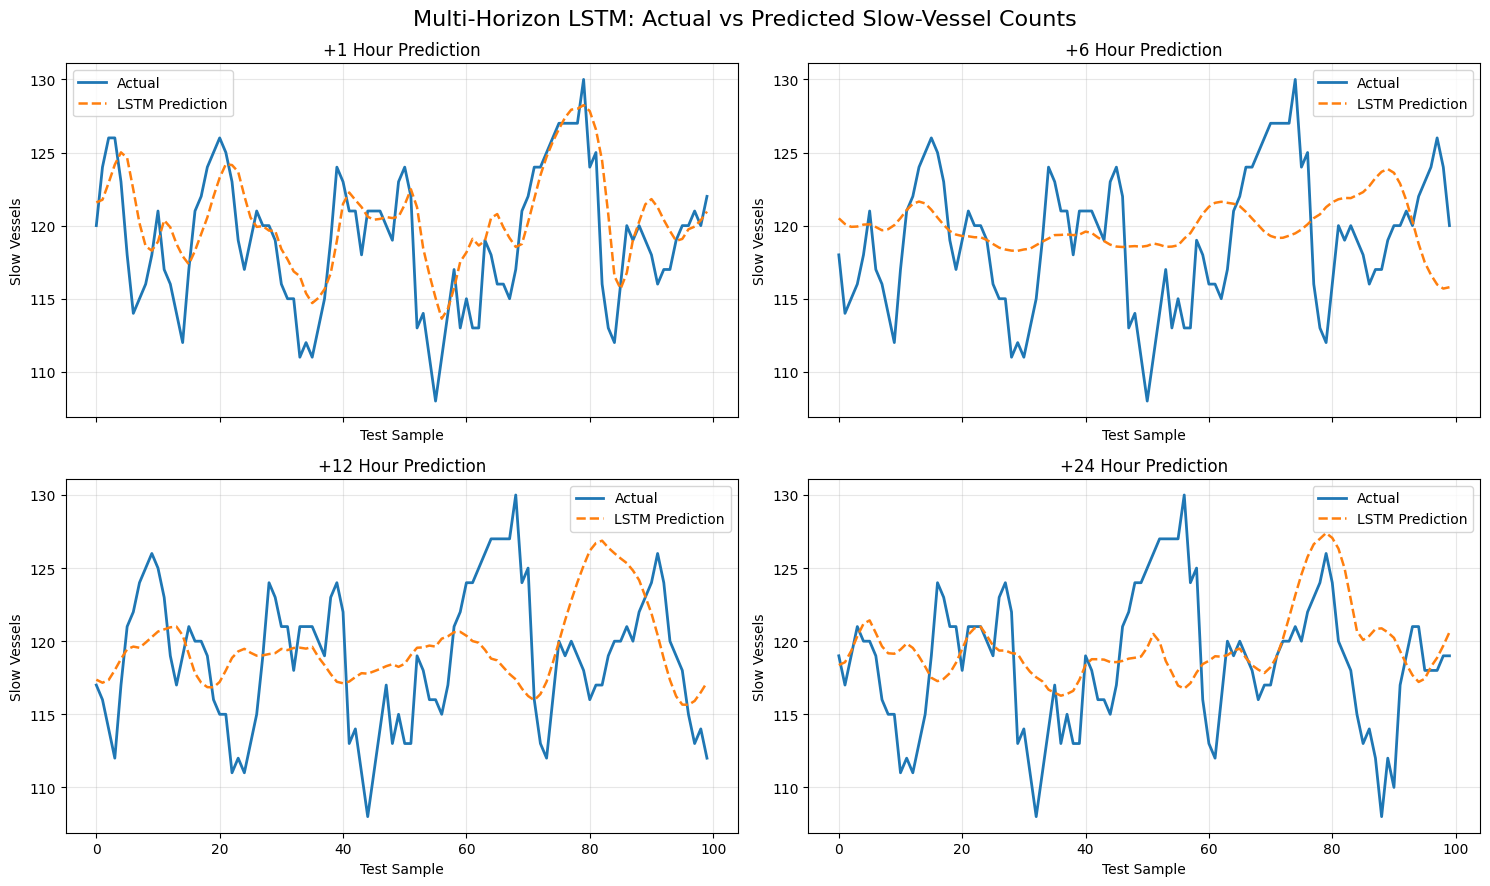

In [31]:
#Plot actual vs. predicted values
import matplotlib.pyplot as plt


horizons = [1, 6, 12, 24]

fig, axes = plt.subplots(
    2, 2,
    figsize=(15, 9),
    sharex=True
)

# Display the first 100 test predictions
n_plot = min(100, len(y_true))

for i, ax in enumerate(axes.flat):

    ax.plot(
        y_true[:n_plot, i],
        label="Actual",
        linewidth=2
    )

    ax.plot(
        y_pred[:n_plot, i],
        label="LSTM Prediction",
        linewidth=1.8,
        linestyle="--"
    )

    ax.set_title(f"+{horizons[i]} Hour Prediction")
    ax.set_xlabel("Test Sample")
    ax.set_ylabel("Slow Vessels")
    ax.legend()
    ax.grid(True, alpha=0.3)

plt.suptitle(
    "Multi-Horizon LSTM: Actual vs Predicted Slow-Vessel Counts",
    fontsize=16
)

plt.tight_layout()

plt.savefig(
    "/content/drive/MyDrive/LSTM_Actual_vs_Predicted.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

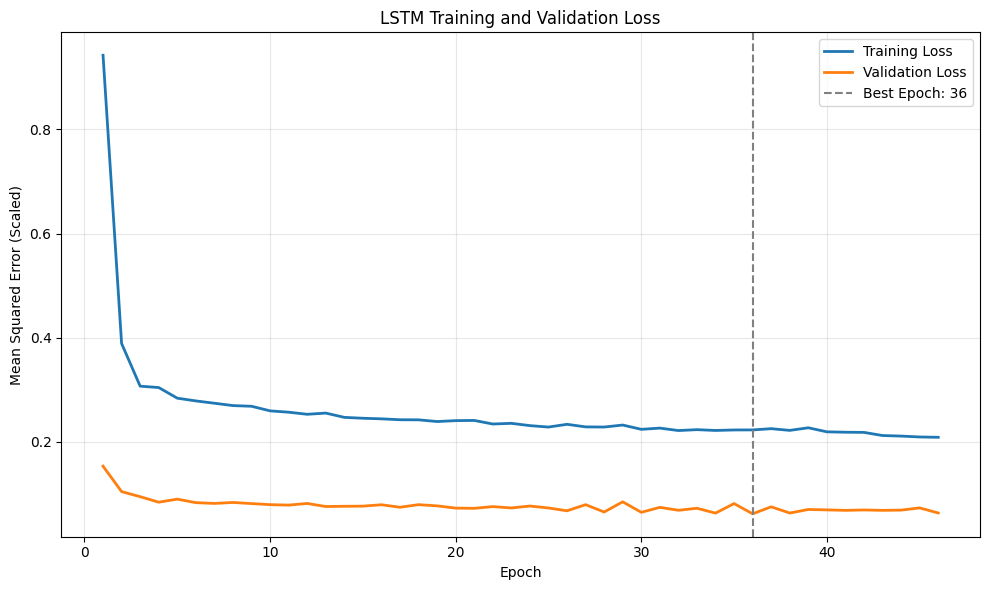

Best epoch: 36
Best validation loss: 0.0615


In [32]:
#Plot training and validation loss
train_loss = history.history["loss"]
val_loss = history.history["val_loss"]

epochs = np.arange(1, len(train_loss) + 1)

plt.figure(figsize=(10, 6))

plt.plot(
    epochs,
    train_loss,
    label="Training Loss",
    linewidth=2
)

plt.plot(
    epochs,
    val_loss,
    label="Validation Loss",
    linewidth=2
)

best_epoch = np.argmin(val_loss) + 1

plt.axvline(
    best_epoch,
    linestyle="--",
    color="gray",
    label=f"Best Epoch: {best_epoch}"
)

plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error (Scaled)")
plt.title("LSTM Training and Validation Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    "/content/drive/MyDrive/LSTM_Training_Validation_Loss.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Best epoch:", best_epoch)
print("Best validation loss:", round(min(val_loss), 4))

In [33]:
#Compare LSTM with a persistence baseline
from sklearn.metrics import mean_absolute_error

# Feature order:
# 0 = ActiveVessels
# 1 = SlowVessels
# 2 = MeanSpeed

# Most recently observed slow-vessel count
last_slow = X_test[:, -1, 1]

# Predict the same count for all four horizons
baseline_pred = np.repeat(
    last_slow[:, None],
    4,
    axis=1
)

comparison = []

for i, horizon in enumerate([1, 6, 12, 24]):

    actual = y_test[:, i]

    lstm_mae = mean_absolute_error(
        actual,
        y_pred[:, i]
    )

    baseline_mae = mean_absolute_error(
        actual,
        baseline_pred[:, i]
    )

    improvement = (
        (baseline_mae - lstm_mae)
        / baseline_mae * 100
        if baseline_mae > 0
        else np.nan
    )

    comparison.append({
        "Horizon": f"+{horizon}h",
        "LSTM_MAE": round(lstm_mae, 3),
        "Baseline_MAE": round(baseline_mae, 3),
        "LSTM_Improvement_%": round(improvement, 2)
    })

comparison_df = pd.DataFrame(comparison)

print("LSTM vs Persistence Baseline")
display(comparison_df)

LSTM vs Persistence Baseline


,Horizon,LSTM_MAE,Baseline_MAE,LSTM_Improvement_%
0,+1h,2.621,2.027,-29.27
1,+6h,5.147,5.723,10.06
2,+12h,5.674,7.505,24.40
3,+24h,6.014,5.897,-2.00


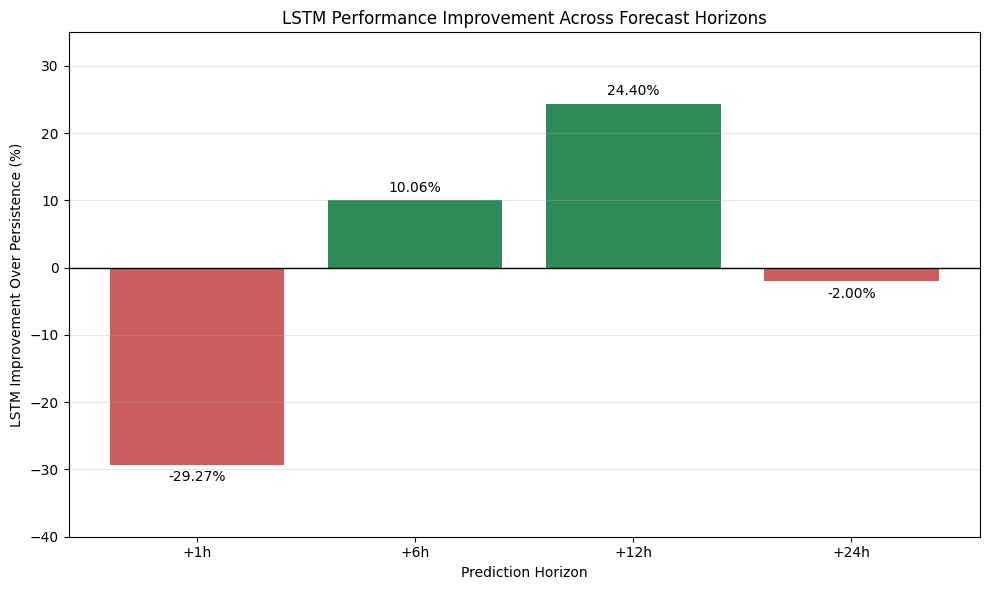

In [34]:
#Visualize LSTM improvement over baseline

horizons = ["+1h", "+6h", "+12h", "+24h"]
improvement = [-29.27, 10.06, 24.40, -2.00]

colors = [
    "seagreen" if value > 0 else "indianred"
    for value in improvement
]

plt.figure(figsize=(10, 6))

bars = plt.bar(
    horizons,
    improvement,
    color=colors
)

plt.axhline(0, color="black", linewidth=1)

plt.bar_label(
    bars,
    fmt="%.2f%%",
    padding=4
)

plt.xlabel("Prediction Horizon")
plt.ylabel("LSTM Improvement Over Persistence (%)")
plt.title("LSTM Performance Improvement Across Forecast Horizons")

plt.ylim(-40, 35)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig(
    "/content/drive/MyDrive/LSTM_Baseline_Improvement.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [35]:
#Create a stricter chronological split
# Load the original hourly dataset
hourly = pd.read_csv(
    "/content/drive/MyDrive/houston_hourly_congestion_2023.csv",
    parse_dates=["Hour"]
).sort_values("Hour").reset_index(drop=True)

features = ["ActiveVessels", "SlowVessels", "MeanSpeed"]
horizons = [1, 6, 12, 24]
lookback = 24

values = hourly[features].to_numpy(dtype=np.float32)

# Split the timeline before constructing sequences
n_hours = len(hourly)
train_boundary = int(n_hours * 0.70)
val_boundary = int(n_hours * 0.85)

datasets = {
    "train": (0, train_boundary),
    "val": (train_boundary, val_boundary),
    "test": (val_boundary, n_hours)
}

def build_sequences(start, end):
    X_part, y_part = [], []

    for t in range(start + lookback - 1, end - max(horizons)):
        x_window = values[t - lookback + 1:t + 1]

        y_window = np.array(
            [values[t + h, 1] for h in horizons],
            dtype=np.float32
        )

        if np.isnan(x_window).any() or np.isnan(y_window).any():
            continue

        X_part.append(x_window)
        y_part.append(y_window)

    return (
        np.array(X_part, dtype=np.float32).reshape(-1, lookback, 3),
        np.array(y_part, dtype=np.float32).reshape(-1, 4)
    )

X_train, y_train = build_sequences(*datasets["train"])
X_val, y_val = build_sequences(*datasets["val"])
X_test, y_test = build_sequences(*datasets["test"])

print("Strict chronological split:")
print("Training:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Testing:", X_test.shape, y_test.shape)

print("\nTimeline boundaries:")
print("Train ends:", hourly.loc[train_boundary - 1, "Hour"])
print("Validation starts:", hourly.loc[train_boundary, "Hour"])
print("Test starts:", hourly.loc[val_boundary, "Hour"])

Strict chronological split:
Training: (865, 24, 3) (865, 4)
Validation: (100, 24, 3) (100, 4)
Testing: (166, 24, 3) (166, 4)

Timeline boundaries:
Train ends: 2023-02-11 06:00:00+00:00
Validation starts: 2023-02-11 07:00:00+00:00
Test starts: 2023-02-20 03:00:00+00:00


In [36]:
from sklearn.preprocessing import StandardScaler

# New scalers for the strict chronological split
feature_scaler = StandardScaler()
target_scaler = StandardScaler()

n_features = X_train.shape[2]

# Fit ONLY on training data
feature_scaler.fit(
    X_train.reshape(-1, n_features)
)

target_scaler.fit(y_train)

# Scale inputs
X_train_scaled = feature_scaler.transform(
    X_train.reshape(-1, n_features)
).reshape(X_train.shape)

X_val_scaled = feature_scaler.transform(
    X_val.reshape(-1, n_features)
).reshape(X_val.shape)

X_test_scaled = feature_scaler.transform(
    X_test.reshape(-1, n_features)
).reshape(X_test.shape)

# Scale targets
y_train_scaled = target_scaler.transform(y_train)
y_val_scaled = target_scaler.transform(y_val)
y_test_scaled = target_scaler.transform(y_test)

print("Scaling completed successfully!")

print("\nTraining:", X_train_scaled.shape)
print("Validation:", X_val_scaled.shape)
print("Testing:", X_test_scaled.shape)

print("\nTraining feature means:")
print(np.round(feature_scaler.mean_, 3))

print("\nTraining feature standard deviations:")
print(np.round(feature_scaler.scale_, 3))

print("\nTraining target means:")
print(np.round(target_scaler.mean_, 3))

Scaling completed successfully!

Training: (865, 24, 3)
Validation: (100, 24, 3)
Testing: (166, 24, 3)

Training feature means:
[147.868 134.087   1.142]

Training feature standard deviations:
[20.532 20.368  0.409]

Training target means:
[133.726 133.607 133.264 132.57 ]


In [37]:
#Retrain the multi-horizon LSTM
import tensorflow as tf

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, LSTM, Dropout, Dense
from tensorflow.keras.callbacks import EarlyStopping

# Reproducibility
tf.keras.utils.set_random_seed(42)

# Create a NEW model
model_strict = Sequential([
    Input(shape=(24, 3)),
    LSTM(64),
    Dropout(0.2),
    Dense(4)
])

# Compile
model_strict.compile(
    optimizer="adam",
    loss="mse",
    metrics=["mae"]
)

# Early stopping
early_stop_strict = EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True
)

# Train on the new chronological split
history_strict = model_strict.fit(
    X_train_scaled,
    y_train_scaled,
    validation_data=(
        X_val_scaled,
        y_val_scaled
    ),
    epochs=50,
    batch_size=32,
    callbacks=[early_stop_strict],
    shuffle=False,
    verbose=1
)

print("\nTraining completed!")

print(
    "Epochs trained:",
    len(history_strict.history["loss"])
)

print(
    "Best epoch:",
    np.argmin(history_strict.history["val_loss"]) + 1
)

print(
    "Best validation loss:",
    round(min(history_strict.history["val_loss"]), 4)
)

model_strict.summary()

Epoch 1/50
28/28 ━━━━━━━━━━━━━━━━━━━━ 5s 45ms/step - loss: 0.9422 - mae: 0.7817 - val_loss: 0.1251 - val_mae: 0.2751
Epoch 2/50
28/28 ━━━━━━━━━━━━━━━━━━━━ 1s 28ms/step - loss: 0.3845 - mae: 0.4142 - val_loss: 0.1165 - val_mae: 0.2858
Epoch 3/50
28/28 ━━━━━━━━━━━━━━━━━━━━ 1s 40ms/step - loss: 0.3071 - mae: 0.3413 - val_loss: 0.1214 - val_mae: 0.2934
Epoch 4/50
28/28 ━━━━━━━━━━━━━━━━━━━━ 1s 41ms/step - loss: 0.2935 - mae: 0.3311 - val_loss: 0.1021 - val_mae: 0.2633
Epoch 5/50
28/28 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - loss: 0.2894 - mae: 0.3227 - val_loss: 0.1022 - val_mae: 0.2633
Epoch 6/50
28/28 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - loss: 0.2804 - mae: 0.3122 - val_loss: 0.1102 - val_mae: 0.2753
Epoch 7/50
28/28 ━━━━━━━━━━━━━━━━━━━━ 1s 27ms/step - loss: 0.2702 - mae: 0.3010 - val_loss: 0.0964 - val_mae: 0.2518
Epoch 8/50
28/28 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - loss: 0.2723 - mae: 0.3027 - val_loss: 0.1046 - val_mae: 0.2659
Epoch 9/50
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 0.261

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_1 (LSTM)                   │ (None, 64)             │        17,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │           260 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 53,006 (207.06 KB)

 Trainable params: 17,668 (69.02 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 35,338 (138.04 KB)

What we're checking
We want to see whether the model still learns useful forecasting patterns when training, validation and testing are separated by time.
the earlier model achieved a best validation loss of 0.0615, but the new validation period is different. Therefore, a higher or lower loss does not automatically mean the model is better or worse.
Also, the model still predicts our preliminary slow-vessel activity proxy, not verified port congestion.

In [38]:
#Evaluate the retrained LSTM against persistence

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Predictions from the retrained LSTM
y_pred_strict_scaled = model_strict.predict(
    X_test_scaled,
    verbose=0
)

# Convert back to vessel counts
y_pred_strict = target_scaler.inverse_transform(
    y_pred_strict_scaled
)

# Actual values in original units
y_true_strict = y_test

# Persistence: repeat the latest observed slow-vessel count
baseline_strict = np.repeat(
    X_test[:, -1, 1].reshape(-1, 1),
    repeats=4,
    axis=1
)

results_strict = []

for i, h in enumerate([1, 6, 12, 24]):

    actual = y_true_strict[:, i]
    predicted = y_pred_strict[:, i]
    baseline = baseline_strict[:, i]

    lstm_mae = mean_absolute_error(actual, predicted)
    baseline_mae = mean_absolute_error(actual, baseline)

    lstm_rmse = np.sqrt(
        mean_squared_error(actual, predicted)
    )

    lstm_r2 = r2_score(actual, predicted)

    improvement = (
        (baseline_mae - lstm_mae)
        / baseline_mae * 100
        if baseline_mae > 0
        else np.nan
    )

    results_strict.append({
        "Horizon": f"+{h}h",
        "LSTM_MAE": round(lstm_mae, 3),
        "LSTM_RMSE": round(lstm_rmse, 3),
        "LSTM_R2": round(lstm_r2, 3),
        "Baseline_MAE": round(baseline_mae, 3),
        "Improvement_%": round(improvement, 2)
    })

results_strict_df = pd.DataFrame(results_strict)

print("Strict Chronological Test Results:")
display(results_strict_df)

Strict Chronological Test Results:


,Horizon,LSTM_MAE,LSTM_RMSE,LSTM_R2,Baseline_MAE,Improvement_%
0,+1h,2.510,3.147,0.881,1.964,-27.82
1,+6h,4.901,6.294,0.559,5.759,14.89
2,+12h,5.752,7.214,0.469,7.663,24.93
3,+24h,6.231,8.696,0.242,6.102,-2.11


We'll see whether the LSTM still improves on persistence at +6h and +12h after changing the evaluation split.
A positive improvement percentage means the LSTM is better; a negative percentage means persistence is better.

In [39]:
#Save trained LSTM and evaluation results
import joblib

folder = "/content/drive/MyDrive"

# Save trained model
model_path = os.path.join(
    folder,
    "houston_lstm_strict.keras"
)

model_strict.save(model_path)

# Save feature scaler
joblib.dump(
    feature_scaler,
    os.path.join(folder, "houston_feature_scaler.pkl")
)

# Save target scaler
joblib.dump(
    target_scaler,
    os.path.join(folder, "houston_target_scaler.pkl")
)

# Save evaluation results
results_strict_df.to_csv(
    os.path.join(folder, "houston_lstm_strict_results.csv"),
    index=False
)

print("Model saved:", model_path)
print("Feature scaler saved.")
print("Target scaler saved.")
print("Evaluation results saved.")

Model saved: /content/drive/MyDrive/houston_lstm_strict.keras
Feature scaler saved.
Target scaler saved.
Evaluation results saved.


**Identify vessels with sustained low-speed activity**
Our previous indicator counted a vessel as slow if it reported SOG ≤ 0.5 knots even once during an hour.
That can overestimate congestion because a vessel might slow down briefly while maneuvering.
This time, we'll use a stricter definition:
A vessel is classified as sustained-low-speed during an hour when:
- It has at least 3 valid AIS speed observations.
- At least 80% of those observations report SOG ≤ 0.5 knots.
- Its observations span at least 20 minutes within that hour.
These are experimental thresholds, not official port-congestion definitions. They help us distinguish sustained low-speed activity from isolated observations, but they still cannot establish whether a vessel is waiting for a berth.


In [40]:

path = (
    "/content/drive/MyDrive/"
    "houston_commercial_AIS_clean_2023.parquet"
)

# Load only the columns needed
ais = pd.read_parquet(
    path,
    columns=["MMSI", "BaseDateTime", "SOG"]
)

ais["BaseDateTime"] = pd.to_datetime(
    ais["BaseDateTime"],
    utc=True
)

# Group observations by hour
ais["Hour"] = ais["BaseDateTime"].dt.floor("h")

# Valid slow-speed observations
ais["IsSlow"] = ais["SOG"] <= 0.5

# Summarize each vessel within each hour
vessel_hour = (
    ais.groupby(["Hour", "MMSI"])
    .agg(
        Observations=("SOG", "count"),
        SlowObservations=("IsSlow", "sum"),
        FirstSeen=("BaseDateTime", "min"),
        LastSeen=("BaseDateTime", "max")
    )
    .reset_index()
)

# Calculate proportion of slow observations
vessel_hour["SlowRatio"] = (
    vessel_hour["SlowObservations"]
    / vessel_hour["Observations"].replace(0, np.nan)
)

# Duration between first and last observation
vessel_hour["ObservedSpanMinutes"] = (
    vessel_hour["LastSeen"] - vessel_hour["FirstSeen"]
).dt.total_seconds() / 60

# New sustained-low-speed classification
vessel_hour["SustainedSlow"] = (
    (vessel_hour["Observations"] >= 3)
    & (vessel_hour["SlowRatio"] >= 0.80)
    & (vessel_hour["ObservedSpanMinutes"] >= 20)
)

print("Total vessel-hour records:", len(vessel_hour))

print(
    "Sustained-low-speed vessel-hours:",
    vessel_hour["SustainedSlow"].sum()
)

print(
    "Percentage classified as sustained slow:",
    round(vessel_hour["SustainedSlow"].mean() * 100, 2),
    "%"
)

print("\nExample vessel-hour records:")
display(
    vessel_hour[
        [
            "Hour",
            "MMSI",
            "Observations",
            "SlowRatio",
            "ObservedSpanMinutes",
            "SustainedSlow"
        ]
    ].head(10)
)

Total vessel-hour records: 200457
Sustained-low-speed vessel-hours: 172730
Percentage classified as sustained slow: 86.17 %

Example vessel-hour records:


,Hour,MMSI,Observations,SlowRatio,ObservedSpanMinutes,SustainedSlow
0,2023-01-01 00:00:00+00:00,209156000,20,1.0,57.016667,True
1,2023-01-01 00:00:00+00:00,209559000,3,1.0,27.000000,True
2,2023-01-01 00:00:00+00:00,215035000,17,1.0,56.950000,True
3,2023-01-01 00:00:00+00:00,215071000,15,1.0,57.016667,True
4,2023-01-01 00:00:00+00:00,215497000,20,1.0,57.000000,True
5,2023-01-01 00:00:00+00:00,215517000,20,1.0,57.050000,True
6,2023-01-01 00:00:00+00:00,215796000,20,1.0,56.983333,True
7,2023-01-01 00:00:00+00:00,215896000,18,1.0,57.000000,True
8,2023-01-01 00:00:00+00:00,219151000,18,1.0,56.950000,True
9,2023-01-01 00:00:00+00:00,219310000,18,1.0,56.983333,True


What does 86.17% mean?
It means 86.17% of the observed vessel-hour records met our sustained-low-speed criteria. It does not mean 86.17% of vessels were congested.
The high percentage suggests that many commercial vessels in our broad Houston study area remain slow for extended periods. They may be berthed, anchored or engaged in other stationary activities.
This confirms why obtaining official geographic boundaries will eventually be important.

In [41]:
#Create and compare the improved hourly congestion indicator
# Load our original hourly indicators
hourly_old = pd.read_csv(
    os.path.join(folder, "houston_hourly_congestion_2023.csv"),
    parse_dates=["Hour"]
)

# Count sustained-low-speed vessels per hour
sustained_hourly = (
    vessel_hour.groupby("Hour")["SustainedSlow"]
    .sum()
    .reset_index(name="SustainedSlowVessels")
)

# Merge with original hourly data
hourly_improved = hourly_old.merge(
    sustained_hourly,
    on="Hour",
    how="left"
)

# Preserve hours with no AIS observations as missing
hourly_improved.loc[
    hourly_improved["ActiveVessels"].isna(),
    "SustainedSlowVessels"
] = np.nan

# Save the improved dataset
output_path = os.path.join(
    folder,
    "houston_hourly_congestion_improved_2023.csv"
)

hourly_improved.to_csv(output_path, index=False)

print("Total hours:", len(hourly_improved))

print(
    "Missing hours:",
    hourly_improved["SustainedSlowVessels"].isna().sum()
)

print("\nComparison of hourly indicators:")
display(
    hourly_improved[
        ["SlowVessels", "SustainedSlowVessels"]
    ].describe()
)

print("\nFirst 10 hours:")
display(
    hourly_improved[
        ["Hour", "ActiveVessels",
         "SlowVessels", "SustainedSlowVessels"]
    ].head(10)
)

print("\nSaved:", output_path)

Total hours: 1416
Missing hours: 16

Comparison of hourly indicators:


,SlowVessels,SustainedSlowVessels
count,1400.000000,1400.000000
mean,129.911429,123.378571
std,18.242764,18.940171
min,1.000000,0.000000
25%,117.000000,110.000000
50%,126.000000,120.000000
75%,144.000000,137.250000
max,177.000000,169.000000



First 10 hours:


,Hour,ActiveVessels,SlowVessels,SustainedSlowVessels
0,2023-01-01 00:00:00+00:00,170.0,152.0,149.0
1,2023-01-01 01:00:00+00:00,169.0,153.0,148.0
2,2023-01-01 02:00:00+00:00,169.0,154.0,147.0
3,2023-01-01 03:00:00+00:00,166.0,152.0,151.0
4,2023-01-01 04:00:00+00:00,169.0,154.0,150.0
5,2023-01-01 05:00:00+00:00,170.0,159.0,154.0
6,2023-01-01 06:00:00+00:00,169.0,161.0,160.0
7,2023-01-01 07:00:00+00:00,170.0,163.0,161.0
8,2023-01-01 08:00:00+00:00,167.0,163.0,162.0
9,2023-01-01 09:00:00+00:00,166.0,162.0,161.0



Saved: /content/drive/MyDrive/houston_hourly_congestion_improved_2023.csv


The new SustainedSlowVessels count should generally be lower than or equal to SlowVessels, because the sustained-speed definition is stricter.
We'll examine how much the count decreases before deciding whether this is a better target for the LSTM.

The new indicator reduces the average count by approximately 6.53 vessels per hour (5.03%).
This confirms that requiring sustained low-speed activity removes some vessels that were previously classified as slow based on a single observation.
However, the improved indicator still includes many stationary vessels, potentially including berthed ships. We should therefore call it sustained low-speed vessel activity, not confirmed congestion.

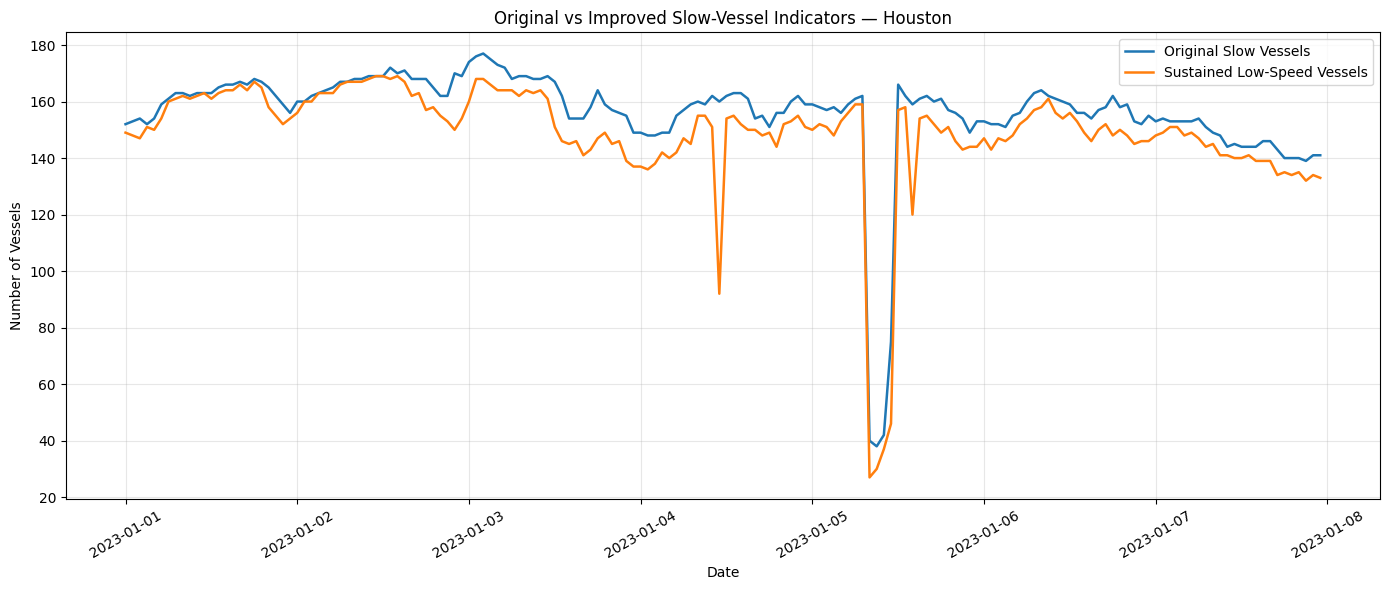

In [42]:
#Visualize the original and improved indicators
# Load improved hourly dataset
hourly_improved = pd.read_csv(
    "/content/drive/MyDrive/houston_hourly_congestion_improved_2023.csv",
    parse_dates=["Hour"]
)

# Select the first 7 days
plot_data = hourly_improved[
    (hourly_improved["Hour"] >= "2023-01-01")
    & (hourly_improved["Hour"] < "2023-01-08")
].copy()

plt.figure(figsize=(14, 6))

plt.plot(
    plot_data["Hour"],
    plot_data["SlowVessels"],
    label="Original Slow Vessels",
    linewidth=1.8
)

plt.plot(
    plot_data["Hour"],
    plot_data["SustainedSlowVessels"],
    label="Sustained Low-Speed Vessels",
    linewidth=1.8
)

plt.xlabel("Date")
plt.ylabel("Number of Vessels")
plt.title(
    "Original vs Improved Slow-Vessel Indicators — Houston"
)

plt.legend()
plt.grid(alpha=0.3)
plt.xticks(rotation=30)
plt.tight_layout()

plt.savefig(
    "/content/drive/MyDrive/Houston_Congestion_Indicators_Comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

We'll see how much the sustained-low-speed definition changes the hourly counts and whether both indicators follow similar temporal patterns.
This comparison is useful for documenting your congestion-indicator engineering methodology in the thesis.

What the diagram shows
- The two indicators follow similar overall trends.
- SustainedSlowVessels is generally lower than SlowVessels, as expected.
- Around January 4–5, there are several unusually sharp drops, including one where both indicators fall to approximately 30–40 vessels.
Important: Those sudden drops may reflect incomplete AIS coverage rather than genuine changes in port activity. We should investigate them before retraining the LSTM, because the model might otherwise learn artificial congestion fluctuations.

In [43]:
#Investigate suspicious hourly drops
# Count AIS messages per hour
ais["Hour"] = ais["BaseDateTime"].dt.floor("h")

message_counts = (
    ais.groupby("Hour")
    .size()
    .reset_index(name="AIS_Messages")
)

# Add message counts to hourly indicators
hourly_check = hourly_improved.merge(
    message_counts,
    on="Hour",
    how="left"
)

# Examine hours with unusually low vessel counts
suspicious = hourly_check[
    hourly_check["ActiveVessels"] < 80
].copy()

print("Hours with fewer than 80 active vessels:",
      len(suspicious))

display(
    suspicious[
        [
            "Hour",
            "ActiveVessels",
            "SlowVessels",
            "SustainedSlowVessels",
            "AIS_Messages"
        ]
    ].sort_values("Hour")
)

Hours with fewer than 80 active vessels: 4


,Hour,ActiveVessels,SlowVessels,SustainedSlowVessels,AIS_Messages
104,2023-01-05 08:00:00+00:00,44.0,40.0,27.0,511.0
105,2023-01-05 09:00:00+00:00,44.0,38.0,30.0,520.0
106,2023-01-05 10:00:00+00:00,49.0,42.0,37.0,729.0
659,2023-01-28 11:00:00+00:00,1.0,1.0,0.0,1.0


The January 28 observation is particularly suspicious: only one AIS message was received, immediately before the eight-hour gap we identified earlier.
The January 5 observations are also unusual because vessel counts fall sharply for three consecutive hours.
These are likely candidates for AIS coverage problems, although the counts alone cannot prove the cause.